In [1]:
#!/usr/bin/env python
import numpy as np

import os, sys
sys.path.append('/home/cercache/users/atarasen/codes/python/')
import nice_functions as nf
import nice_functions2 as nf2
import ncdfView as nv

import plot_stereo
reload(plot_stereo)

sys.path.append('/home3/homedir7/perso/atarasen/codes/python/collocation')
import buoy as buoy_module
reload (buoy_module)

import S1_open_process_and_visu as S1_open
reload (S1_open)


import buoy as buoy_module
reload (buoy_module)

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.basemap import Basemap

import scipy.io
from scipy import ndimage
import cv2


import datetime

No extra plotting objects loaded...


In [2]:
sys.path.append('/home3/homedir7/perso/atarasen/codes/python/posada/')
sys.path.append('/home3/homedir7/perso/atarasen/codes/python/cmod/')


from posada.Handlers.sar import SAR
from posada.Models.swath import Swath
from posada.Readers.safe import SAFEGeoTiffFile


In [3]:
def s1(fn, pol='hh', spacing_m=500):
    sarf = SAFEGeoTiffFile(url=fn, polarization=pol)
    sarf.open()
    sw = Swath()
    sw.load(sarf)
    sar = SAR(sw)

    spacing = np.int0(sar.meters2pixels(spacing_m))
    #ssr = sar.get_data('roughness', spacing=spacing)
    sigma0 = sar.get_data('sigma0', spacing=spacing)
    ele = sar.get_data('elevation', spacing=spacing)
    inc = sar.get_data('incidence', spacing=spacing)
    lat = sar.get_data('lat', spacing=spacing)
    lon = sar.get_data('lon', spacing=spacing)
    return sigma0, lat, lon, inc, ele

def s1_simple_processing(ice_data, elev_angle, pol='hh'):

    mat= scipy.io.loadmat('/home/cercache/users/atarasen/codes/matlab/NESZ_water.mat')
    elev_vector=np.ndarray.tolist(mat['elev_vector'][0])
    ele_step=elev_vector[1]-elev_vector[0]
    if pol == 'hh':
        nesz = np.ndarray.tolist(mat['nesz_HH'][0])
    elif pol =='hv':
        nesz = np.ndarray.tolist(mat['nesz_HV'][0])

#     for ix in sigma0[:, 0].shape:
#           sigma_mean=np.mean(sigma0,0)        
#     plt.plot(np.median(elev_angle,0),sigma_mean)
#     plt.plot(np.mean(elev_angle,0),sigma_mean)

#     plt.plot(elev_vector, nesz)
#     plt.title(pol)        
#     plt.show()
#     nf.pause()
#     plt.close()
    
    data_corr=np.ones(ice_data.shape)
    for i, v in enumerate(elev_vector):
        r, c = np.where(np.logical_and((v-ele_step/2)<elev_angle, elev_angle<=(v+ele_step/2)))
        if not(r.any())==False:
            data_corr[r, c] = ice_data[r, c] - nesz[i]   
    data_corr_lg = np.multiply(np.log10(data_corr), 10)
    
    return data_corr, data_corr_lg
    
    
# def regrid_buoy2s1(buoy_lat, buoy_lon, S1_lat, S1_lon):
#     return buoy_lat_new, buoy_lon_new



# def regrid2icegrid(var, lat, lon):
# #     may be create a land mask from any random ice product? one and forever?..

#     path_grid='/home/cercache/users/atarasen/data/SSMI/grid_north_12km.nc'
#     nc_grid=nv.ncdfView(path_grid, Quiet=True)
#     lon_ice=nc_grid('longitude')
#     lat_ice=nc_grid('latitude')    
  
#     var_icegrid=scipy.interpolate.griddata((lat.flatten(), lon.flatten()),var.flatten() , (lat_ice, lon_ice),method='nearest')   
    
#     return var_icegrid

In [4]:
def sobel_filter(sigma0, pol,  plot=False, S1_name=None):
    sigma=np.multiply(np.log(sigma0), 10)
    sx = ndimage.sobel(sigma, axis=0, mode='constant')
    sy = ndimage.sobel(sigma, axis=1, mode='constant')
    sob_sigma = np.hypot(sx, sy) # (sx**2+sy**2)**0.5
    
    if plot==True:
#         col_map = plt.get_cmap('gist_heat')
        col_map = plt.get_cmap('jet')

        plt.imshow(sob_sigma, cmap=col_map)
        plt.clim(0,50)
#         plt.colorbar()
        plt.title(S1_name[:32]+"..."+S1_name[-4:]+"\n pol = "+pol)
    #     plt.savefig(fig_name, dpi=300)
    #     plt.show()   
    
    
    return sob_sigma

def sobel_filter2(sigma0, pol, x=1, y=1, plot=False, S1_name=None):
    sigma=np.multiply(np.log(sigma0), 10)
    
    sob_sigma = cv2.Sobel(sigma,cv2.CV_64F,x,y,ksize=5)

    
    if plot==True:
#         col_map = plt.get_cmap('gist_heat')
        col_map = plt.get_cmap('jet')

        plt.imshow(sob_sigma, cmap=col_map)
        plt.clim(0,50)
#         plt.colorbar()
        plt.title(S1_name[:32]+"..."+S1_name[-4:]+"\n pol = "+pol)
    #     plt.savefig(fig_name, dpi=300)
    #     plt.show()   
    
    
    return sob_sigma

def laplacian_filter(sigma0, pol,  plot=False, S1_name=None):
    lapl_sigma = cv2.Laplacian(sigma0,cv2.CV_64F, ksize=5)
    
    if plot==True:
        col_map = plt.get_cmap('jet')
        plt.imshow(sob_sigma, cmap=col_map)
        plt.clim(0,50)
#         plt.colorbar()
        plt.title(S1_name[:32]+"..."+S1_name[-4:]+"\n pol = "+pol)
    #     plt.savefig(fig_name, dpi=300)
    #     plt.show()   
    
    return lapl_sigma

In [5]:
def checkdir_and_create(dir_name):
    import os, sys
    if os.path.isdir(dir_name)==False:
        os.system('mkdir %s' %(dir_name))

Open a new figure
polarization: hh
polarization: hv


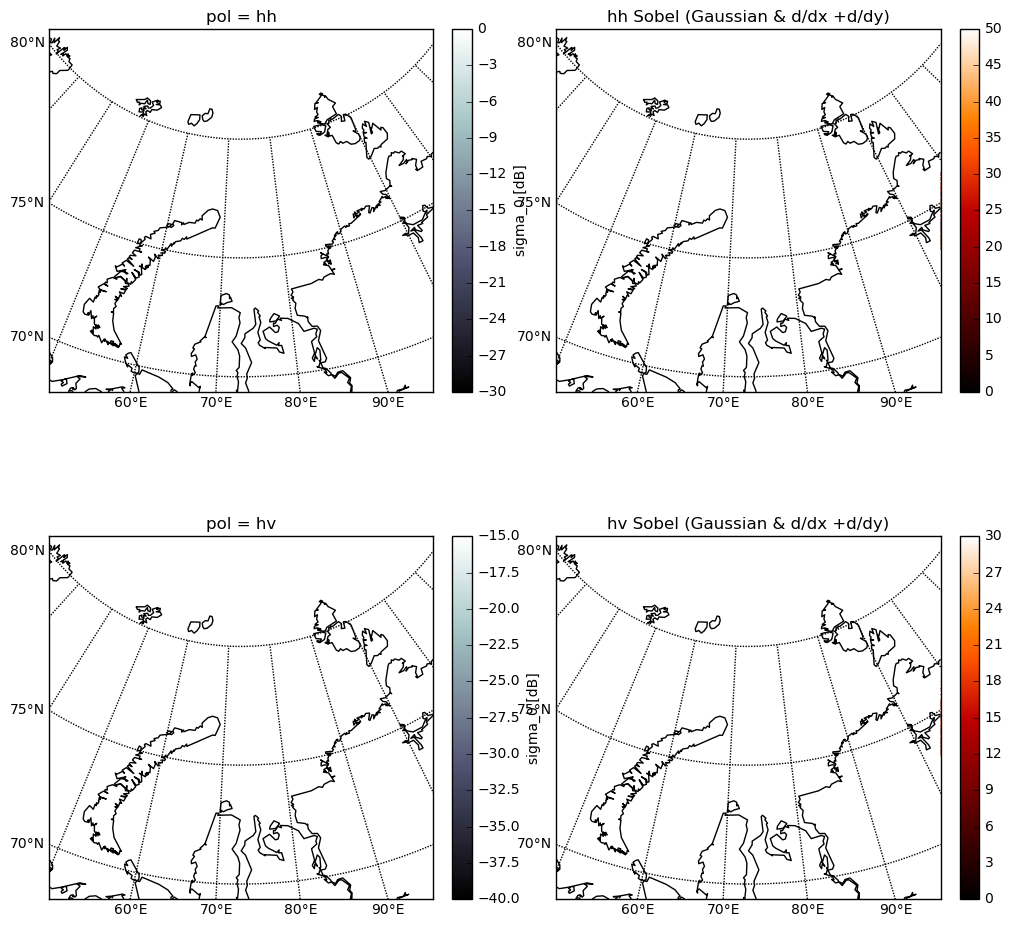

In [16]:
# Example with one file
reload(plot_stereo)
fpathout_fig='/home3/homedir7/perso/atarasen/Figures'


# fpath_0 = '/home/cercache/users/atarasen/data/Sentinel-1_analysis/Kara/'
# filename ='S1A_EW_GRDH_1SDH_20141003T234105_20141003T234157_002672_002FA5_D6D8.zip'
# filename = 'S1A_EW_GRDH_1SDH_20141003T133957_20141003T134057_002666_002F83_0BE7.zip'

fpath_0 = '/home/cercache/users/atarasen/data/Sentinel-1_analysis/S1/Greenland/'
# filename ='S1A_EW_GRDM_1SDH_20141126T080037_20141126T080137_003450_00408D_E326.zip'
# # filename ='S1A_EW_GRDM_1SDH_20141205T073636_20141205T073736_003581_0043A7_3AF6.zip'
# # # filename ='S1A_EW_GRDM_1SDH_20141205T154520_20141205T154620_003586_0043BF_F6E1.zip'
# # filename ='S1A_EW_GRDM_1SDH_20141201T081006_20141201T081106_003523_00424D_5EF1.zip'
# fbuoy_dir= 'itp76rawlocs'




# filename ='S1A_EW_GRDM_1SSH_20151205T042233_20151205T042337_008902_00CBBF_A003.zip'
# filename ='S1A_EW_GRDM_1SDH_20151209T165759_20151209T165859_008968_00CDA8_D6D8.zip'

# fbuoy_dir= '300234060179710'
# fn = dirname + filename
# print(fn)

fig = plt.figure(figsize=(12,12))
spacing=500
print "Open a new figure"

for pol in ['hh', 'hv']:
        print 'polarization:', pol
#     try:
#         sigma0, lat, lon180, inc, ele = S1_open.s1(fpath_0+fbuoy_dir+'/'+filename, pol, spacing_m=spacing)
        sigma0, lat, lon180, inc, ele = S1_open.s1(fpath_0+'/'+filename, pol, spacing_m=spacing)

        lon = plot_stereo.s1_lon360(lon180)
        data_corr, data_corr_lg = S1_open.s1_simple_processing(sigma0, ele, pol)
        sob_sigma = S1_open.sobel_filter(sigma0, pol)


        if pol == 'hh':
            ax1 = fig.add_subplot(221)
        else:
            ax3 = fig.add_subplot(223)
        fig_title1='pol = '+pol
# #         plot_stereo.region(data_corr_lg, lat, lon, filename[:-4], pol+'_log', case='Greenland', \
# #                            area_case='Fram strait', fig_title=fig_title1, buoy_case='itp76rawlocs',\
# #                            col_bar=True)    
        plot_stereo.region(data_corr_lg, lat, lon, filename[:-4], pol+'_log', case='Kara', \
                           area_case='Kara', fig_title=fig_title1, buoy_case=None,\
                           col_bar=True)

#         plot_stereo.Arctic(sigma0, lat, lon180, filename[:-4], pol+'_log', case='Kara', \
#                            fig_title=fig_title1, buoy_case=None,\
#                            col_bar=True)
#         plot_stereo.simple(data_corr_lg, pol)

        if pol == 'hh':
            ax2 = fig.add_subplot(222)  
        else:
            ax4 = fig.add_subplot(224)

        fig_title2= pol + ' Sobel (Gaussian & d/dx +d/dy)'	
# #         plot_stereo.region(sob_sigma, lat, lon, filename[:-4], pol+'_sobel', case='Greenland', \
# #                            area_case='Fram strait', fig_title=fig_title2, buoy_case='itp76rawlocs',\
# #                            col_bar=True)
        plot_stereo.region(sob_sigma, lat, lon, filename[:-4], pol+'_sobel', case='Kara', \
                           area_case='Kara', fig_title=fig_title2, buoy_case=None,\
                           col_bar=True)
#         plot_stereo.Arctic(sob_sigma, lat, lon, filename[:-4], pol+'_sobel', case='Kara', \
#                            fig_title=fig_title2, buoy_case=None,\
#                            col_bar=True)
    

#     except:
#         pass

plt.show()

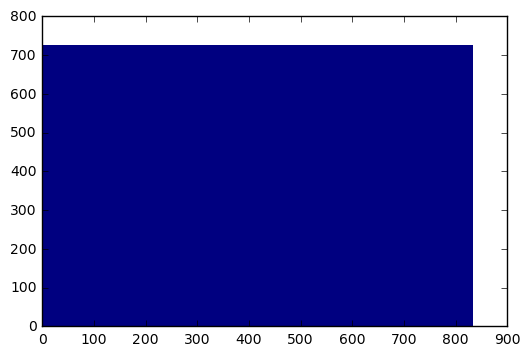

In [11]:
plt.pcolormesh(data_corr_lg)
plt.show()


In [ ]:
reload(plot_stereo)

case_list=['Greenland'] 
buoy_list=['itp76rawlocs']
# , '300234060179710']
for case in case_list:
    fpath_0='/home/cercache/users/atarasen/data/Sentinel-1_analysis/S1/'+case+'/'  #eg 'Greenland' 
    fpathout_fig='/home3/homedir7/perso/atarasen/Figures/'+case+'/Fram_strait'
    checkdir_and_create(fpathout_fig)
            
    fdir_case=os.listdir(fpath_0)
    #print 'fdir_case', fdir_case

#     for fbuoy_dir in buoy_list:    
    for fbuoy_dir in fdir_case:
        if fbuoy_dir=='itp76rawlocs':
            print 'fbuoy_dir', fbuoy_dir            
            fdir=os.listdir(fpath_0+fbuoy_dir)
            print fdir
            for i, fname in enumerate(fdir):
                if fname[-4:]=='.zip':
                    print i, ' from ', len(fdir)
                    print fpath_0+fbuoy_dir+'/'+fname
                    
                    nf.tic()
                    fig_name = fpathout_fig+fbuoy_dir+'_'+fname[17:31]+'_'+fname[-8:-4]+'.png'
                    if os.path.isfile(fig_name)==False or os.path.isfile(fig_name)==True:
                        fig = plt.figure(figsize=(12,12))
                        cond_hh=True; cond_hv=True

                        for pol in ['hh', 'hv']:
                                print 'polarization:', pol
                                if pol=='hh':
#                                     try:
                                        sigma0, lat, lon180, inc, ele = s1(fpath_0+fbuoy_dir+'/'+fname, pol)
                                        lon = plot_stereo.s1_lon360(lon180)
                                        data_corr, data_corr_lg = s1_simple_processing(sigma0, ele, pol)
            #                             sob_sigma= sobel_filter(sigma0, fname[:-4])

                                        ax = fig.add_subplot(221)
                                        plot_stereo.region(data_corr_lg, lat, lon, fname[:-4], pol+'_log',\
                                                           'Greenland', fbuoy_dir, col_bar=False)

                                        ax1=fig.add_subplot(222)
                                        fig_title1='pol = HH'
                                        x, y, x_b, y_b = plot_stereo.region(data_corr_lg, lat, lon, fname[:-4],\
                                                                          pol+'_log', 'Fram strait', fbuoy_dir,\
                                                                          fig_title=fig_title1)

                                        ax2=fig.add_subplot(223)
                                        sob_sigma = sobel_filter(sigma0, pol)
                                        fig_title2='HH + Sobel filter (Gaussian & d/dx +d/dy)'
                                        plot_stereo.region(sob_sigma, lat, lon, fname[:-4], pol+'_sobel', \
                                                         'Fram strait', fbuoy_dir, fig_title=fig_title2,\
                                                         x=x, y=y, x_b=x_b, y_b=y_b)
#                                     except:
#                                         cond_hh=False
#                                         print 'error in reading', pol, 'polarization'
#                                         pass
                                    
                                elif pol=='hv':
                                    try:
                                        sigma0, _, _, _, _ = s1(fpath_0+fbuoy_dir+'/'+fname, pol)
                                        data_corr, data_corr_lg = s1_simple_processing(sigma0, ele, pol)

                                        ax3=fig.add_subplot(224)
                                        fig_title3='pol = HV'
                                        plot_stereo.region(data_corr_lg, lat, lon, fname[:-4], pol+'_log', \
                                                         'Fram strait', fbuoy_dir, fig_title=fig_title3, \
                                                         x=x, y=y, x_b=x_b, y_b=y_b)
                                         
                                    except:
                                        cond_hv=False
                                        print 'error in reading', pol, 'polarization'
                                        pass
                        if cond_hh==True or cond_hv==True:
                                    plt.savefig(fig_name, dpi=300)
                                    print fig_name, ' is created'
                                    plt.show()
#                         plt.close()
                    nf.toc()
                    #del sigma0, sob_sigma, data_corr, data_corr_lg, lon180, lon, lat, x, y, x_y, y_b, ax, ax1, ax2, ax3


In [ ]:
# Experiments with filters
reload(plot_stereo)
dirname = '/home/cercache/users/atarasen/data/Sentinel-1_analysis/S1/Greenland/itp76rawlocs/'
# filename ='S1A_EW_GRDM_1SDH_20141201T211845_20141201T211949_003531_00427A_AF51.zip'
# filename ='S1A_EW_GRDM_1SDH_20141205T073636_20141205T073736_003581_0043A7_3AF6.zip'
# filename ='S1A_EW_GRDM_1SDH_20141205T154520_20141205T154620_003586_0043BF_F6E1.zip'
filename ='S1A_EW_GRDM_1SDH_20141201T081006_20141201T081106_003523_00424D_5EF1.zip'

fbuoy_dir= 'itp76rawlocs'

# dirname = '/home/cercache/users/atarasen/data/Sentinel-1_analysis/S1/Greenland/300234060179710/'
# filename ='S1A_EW_GRDM_1SSH_20151205T042233_20151205T042337_008902_00CBBF_A003.zip'
# fbuoy_dir= '300234060179710'
fn = dirname + filename
print(fn)

pol ='hv'
nf.tic()
sigma0, lat, lon, inc, ele = s1(fn, pol)
nf.toc()

fig = plt.figure(figsize=(12,12))
ax = fig.add_subplot(221)
plot_stereo.zoom(sigma0, lat, lon, filename[:-4], pol, 'Greenland', fbuoy_dir)

ax1 = fig.add_subplot(222)
sob_sigma=sobel_filter2(sigma0, pol, 1, 0, True, filename)

ax2 = fig.add_subplot(223)
lapl_sigma=laplacian_filter(sigma0, pol, True, filename)

ax3 = fig.add_subplot(224)
lapl_sigma=sobel_filter2(sigma0, pol, 0 , 1, True, filename)



# col_map={'hh':'bone', 'hv':'bone', 'hh_log':'bone', 'hv_log':'bone', 'hh_sobel':'gist_heat'}
# plt.imshow(sigma0, cmap=col_map['hh'])

plt.show()

In [ ]:
if __name__ == "__main__":
    case_list=['Greenland'] 
    # buoy_list=['itp76rawlocs', '300234060179710']
    fpathout_fig='/home3/homedir7/perso/atarasen/Figures'

    for case in case_list:
        fpath_0='/home/cercache/users/atarasen/data/Sentinel-1_analysis/S1/'+case+'/' 
        fdir_case=os.listdir(fpath_0)
        #print 'fdir_case', fdir_case

    #     for fbuoy_dir in buoy_list:    
        for fbuoy_dir in fdir_case:
            print 'fbuoy_dir', fbuoy_dir
            if os.path.isdir(fpath_0+fbuoy_dir)==True:
                fdir=os.listdir(fpath_0+fbuoy_dir)
                #print fdir
                for i, fname in enumerate(fdir):
                    if fname[-4:]=='.zip':
                        print fpath_0+fbuoy_dir+'/'+fname
                        nf.tic()
                        fig = plt.figure(figsize=(12,12))
                        fig_name = fpathout_fig+'/'+fbuoy_dir+'_'+fname[17:31]+'_'+fname[-8:-4]+'.png'
                        for pol in ['hh', 'hv']:
                                if os.path.isfile(fig_name)==False:                            
                                    print 'polarization:', pol
                                    if pol=='hh':
                                        sigma0, lat, lon180, inc, ele = s1(fpath_0+fbuoy_dir+'/'+fname, pol)
                                        lon = plot_stereo.s1_lon360(lon180)
                                        data_corr, data_corr_lg = s1_simple_processing(sigma0, ele, pol)
            #                             sob_sigma= sobel_filter(sigma0, fname[:-4])

                                        ax = fig.add_subplot(221)
                                        plot_stereo.region(data_corr_lg, lat, lon, fname[:-4], pol+'_log', 'Greenland', fbuoy_dir)

                                        ax1=fig.add_subplot(222)
                                        fig_title=pol[:]
                                        x, y, x_b, y_b = plot_stereo.zoom(data_corr_lg, lat, lon, fname[:-4], pol+'_log', 'Greenland', fbuoy_dir, fig_title=fig_title)

                                        ax2=fig.add_subplot(223)
                                        sob_sigma = sobel_filter(sigma0, pol)
                                        fig_title=pol+' sobel filter'
                                        plot_stereo.zoom(sob_sigma, lat, lon, fname[:-4], pol+'_sobel', 'Greenland', fbuoy_dir, fig_title=fig_title, x=x, y=y, x_b=x_b, y_b=y_b)

                                    else:
                                        try:
                                            sigma0, _, _, _, _ = s1(fpath_0+fbuoy_dir+'/'+fname, pol)
                                            data_corr, data_corr_lg = s1_simple_processing(sigma0, ele, pol)

                                            ax3=fig.add_subplot(224)
                                            fig_title=pol[:]
                                            plot_stereo.zoom(data_corr_lg, lat, lon, fname[:-4], pol+'_log', 'Greenland', fbuoy_dir, fig_title=fig_title, x=x, y=y, x_b=x_b, y_b=y_b)
                                        
                                    	    plt.savefig(fig_name, dpi=300)
                                        except: 
                                            #pass
                                    	    plt.savefig(fig_name, dpi=300)

                            #plt.show()
                        plt.close()
                        nf.toc()
                        #del sigma0, sob_sigma, data_corr, data_corr_lg, lon180, lon, lat, x, y, x_y, y_b, ax, ax1, ax2, ax3
